<style>
/* Blue Markdown styling for JupyterLab, Notebook 7, and classic Notebook */
.jp-MarkdownOutput,
.text_cell_render {
    color: #0057B7 !important;
    font-size: 17px !important;
    line-height: 1.50 !important;
}
.jp-MarkdownOutput h1,
.jp-MarkdownOutput h2,
.jp-MarkdownOutput h3,
.jp-MarkdownOutput h4,
.text_cell_render h1,
.text_cell_render h2,
.text_cell_render h3,
.text_cell_render h4 {
    color: #0057B7 !important;
    font-weight: 700 !important;
}
.jp-MarkdownOutput mjx-container,
.text_cell_render mjx-container {
    color: #0057B7 !important;
}
</style>




In [1]:

# ============================================================
# 0. Imports and output directory
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.ticker import AutoMinorLocator, MultipleLocator, LogLocator, NullFormatter
from matplotlib.colors import ListedColormap, BoundaryNorm

C_KMS = 299792.458
GEV_TO_FM_INV = 5.067730716
U_TO_GEV = 0.93149410242
ME_GEV = 0.00051099895

FIGDIR = Path.cwd() / "figures_bold_beautiful"
FIGDIR.mkdir(parents=True, exist_ok=True)

print("Output folder:")
print(FIGDIR.resolve())


Output folder:
D:\New_LZ_Projects\LZ_isotopes\figures_bold_beautiful


In [2]:
# ============================================================
# NumPy compatibility
# ============================================================
# This notebook uses np.trapz so it works with older NumPy 1.x
# installations commonly shipped with Anaconda.
print("NumPy version:", np.__version__)
print("Integration routine: np.trapz")


NumPy version: 1.26.4
Integration routine: np.trapz



## 1. Global plotting style


The figure style is controlled globally so every panel uses **large bold axis labels**, **bold tick labels**, and **framed rounded legend boxes** with consistent spacing.


In [3]:
# ============================================================
# 1. Publication plotting style
# ============================================================

plt.rcParams.update({
    "figure.figsize": (9.2, 6.9),
    "figure.dpi": 150,
    "savefig.dpi": 600,
    "font.size": 16,
    "font.weight": "bold",
    "axes.labelsize": 26,
    "axes.labelweight": "bold",
    "axes.titlesize": 20,
    "axes.titleweight": "bold",
    "axes.linewidth": 2.3,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "xtick.major.size": 9,
    "ytick.major.size": 9,
    "xtick.minor.size": 5,
    "ytick.minor.size": 5,
    "xtick.major.width": 2.1,
    "ytick.major.width": 2.1,
    "xtick.minor.width": 1.6,
    "ytick.minor.width": 1.6,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "legend.fontsize": 16,
    "legend.frameon": True,
    "legend.fancybox": True,
    "legend.framealpha": 0.96,
    "legend.shadow": True,
    "lines.linewidth": 2.6,
    "lines.markersize": 8,
    "mathtext.fontset": "stix",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

def make_ticklabels_bold(ax):
    """Make all visible x/y tick labels bold."""
    for tick in ax.get_xticklabels(which="both"):
        tick.set_fontweight("bold")
    for tick in ax.get_yticklabels(which="both"):
        tick.set_fontweight("bold")

def style_legend(leg):
    """Apply the same polished boxed-legend style everywhere."""
    if leg is None:
        return None
    frame = leg.get_frame()
    frame.set_linewidth(1.5)
    return leg

def beautify_axis(
    ax,
    *,
    xminor=2,
    yminor=2,
    grid=True,
    legend=False,
    legend_loc="best",
    legend_ncol=1,
    legend_bbox=None,
):
    ax.tick_params(
        axis="both", which="major",
        direction="in", length=9, width=2.1,
        top=True, right=True, pad=7,
    )
    ax.tick_params(
        axis="both", which="minor",
        direction="in", length=5, width=1.6,
        top=True, right=True,
    )

    if ax.get_xscale() == "linear":
        ax.xaxis.set_minor_locator(AutoMinorLocator(xminor))
    if ax.get_yscale() == "linear":
        ax.yaxis.set_minor_locator(AutoMinorLocator(yminor))

    for spine in ax.spines.values():
        spine.set_linewidth(2.3)

    if grid:
        ax.grid(True, which="major", alpha=0.22, linewidth=0.9)
        ax.grid(True, which="minor", alpha=0.10, linewidth=0.6)

    make_ticklabels_bold(ax)

    if legend:
        kwargs = dict(
            loc=legend_loc,
            ncol=legend_ncol,
            frameon=True,
            fancybox=True,
            framealpha=0.96,
            shadow=True,
            borderpad=0.85,
            labelspacing=0.55,
            handlelength=2.7,
            handletextpad=0.8,
            prop={"size": 16, "weight": "bold"},
        )
        if legend_bbox is not None:
            kwargs["bbox_to_anchor"] = legend_bbox

        leg = ax.legend(**kwargs)
        style_legend(leg)

    return ax

def save_figure(fig, stem, dpi=600):
    pdf = FIGDIR / f"{stem}.pdf"
    png = FIGDIR / f"{stem}.png"
    fig.savefig(pdf, bbox_inches="tight")
    fig.savefig(png, dpi=dpi, bbox_inches="tight")
    print(f"Saved: {pdf.name}")
    print(f"Saved: {png.name}")



## 2. Xenon isotope data

We use the natural xenon abundances and the measured **atomic** isotope masses from NIST.
For the recoil kinematics, we convert these to approximate nuclear masses by subtracting
the rest masses of 54 electrons:

$$
m_A^{\rm nuc}\simeq m_A^{\rm atom}-54\,m_e .
$$

The tiny electronic binding-energy correction is neglected.


In [4]:

# ============================================================
# 2. Xenon isotope inputs
# ============================================================

XE = pd.DataFrame({
    "A": [124, 126, 128, 129, 130, 131, 132, 134, 136],
    "abundance": [0.000952, 0.000890, 0.019102, 0.264006, 0.040710, 0.212324, 0.269086, 0.104357, 0.088573],
    "mass_u_atom": [123.9058920, 125.9042983, 127.9035310, 128.9047808611, 129.903509349, 130.90508406, 131.9041550856, 133.90539466, 135.907214484],
})

XE["mass_GeV_atom"] = XE["mass_u_atom"] * U_TO_GEV
XE["mass_GeV"] = XE["mass_GeV_atom"] - 54.0 * ME_GEV
XE["label"] = [rf"$^{{{A}}}$Xe" for A in XE["A"]]

print("Sum of natural xenon fractions =", XE["abundance"].sum())
XE


Sum of natural xenon fractions = 1.0


,A,abundance,mass_u_atom,mass_GeV_atom,mass_GeV,label
0,124,0.000952,123.905892,115.417608,115.390014,$^{124}$Xe
1,126,0.000890,125.904298,117.279111,117.251517,$^{126}$Xe
2,128,0.019102,127.903531,119.141385,119.113791,$^{128}$Xe
3,129,0.264006,128.904781,120.074043,120.046449,$^{129}$Xe
4,130,0.040710,129.903509,121.004353,120.976759,$^{130}$Xe
5,131,0.212324,130.905084,121.937314,121.909720,$^{131}$Xe
6,132,0.269086,131.904155,122.867943,122.840349,$^{132}$Xe
7,134,0.104357,133.905395,124.732085,124.704491,$^{134}$Xe
8,136,0.088573,135.907214,126.596769,126.569175,$^{136}$Xe



## 3. Core kinematics and response functions


In [5]:

# ============================================================
# 3. Physics functions
# ============================================================

def reduced_mass(mchi_GeV, mA_GeV):
    return (mchi_GeV * mA_GeV) / (mchi_GeV + mA_GeV)

def vmin_inelastic_kms(E_keV, mchi_GeV, delta_keV, mA_GeV):
    E_GeV = np.asarray(E_keV, dtype=float) * 1e-6
    delta_GeV = np.asarray(delta_keV, dtype=float) * 1e-6
    mu = reduced_mass(mchi_GeV, mA_GeV)
    beta_min = ((mA_GeV * E_GeV / mu) + delta_GeV) / np.sqrt(2.0 * mA_GeV * E_GeV)
    return beta_min * C_KMS

def vmin_star_kms(mchi_GeV, delta_keV, mA_GeV):
    mu = reduced_mass(mchi_GeV, mA_GeV)
    delta_GeV = delta_keV * 1e-6
    return np.sqrt(2.0 * delta_GeV / mu) * C_KMS

def E_star_keV(mchi_GeV, delta_keV, mA_GeV):
    mu = reduced_mass(mchi_GeV, mA_GeV)
    return delta_keV * mu / mA_GeV

def recoil_endpoints_keV(v_kms, mchi_GeV, delta_keV, mA_GeV):
    beta = np.asarray(v_kms, dtype=float) / C_KMS
    mu = reduced_mass(mchi_GeV, mA_GeV)
    delta_GeV = delta_keV * 1e-6

    disc = 1.0 - 2.0 * delta_GeV / (mu * beta**2)
    root = np.sqrt(np.maximum(disc, 0.0))

    pref_GeV = (mu**2 * beta**2) / (2.0 * mA_GeV)
    Eminus = pref_GeV * (1.0 - root)**2 * 1e6
    Eplus  = pref_GeV * (1.0 + root)**2 * 1e6

    Eminus = np.where(disc >= 0.0, Eminus, np.nan)
    Eplus  = np.where(disc >= 0.0, Eplus, np.nan)

    return Eminus, Eplus

from math import erf as scalar_erf
try:
    from scipy.special import erf
except Exception:
    erf = np.vectorize(scalar_erf)

def N_escape(v0=238.0, vesc=544.0):
    z = vesc / v0
    return erf(z) - (2.0 / np.sqrt(np.pi)) * z * np.exp(-z**2)

def eta_shm(vmin_kms, v0=238.0, vesc=544.0, vE=250.5):
    vmin = np.asarray(vmin_kms, dtype=float)

    x = vmin / v0
    y = vE / v0
    z = vesc / v0

    Nesc = N_escape(v0=v0, vesc=vesc)
    eta = np.zeros_like(x, dtype=float)

    reg1 = x < (z - y)
    reg2 = (x >= (z - y)) & (x < (z + y))
    reg3 = x >= (z + y)

    eta[reg1] = (
        erf(x[reg1] + y)
        - erf(x[reg1] - y)
        - (4.0 * y / np.sqrt(np.pi)) * np.exp(-z**2)
    ) / (2.0 * Nesc * vE)

    eta[reg2] = (
        erf(z)
        - erf(x[reg2] - y)
        - (2.0 / np.sqrt(np.pi)) * (z + y - x[reg2]) * np.exp(-z**2)
    ) / (2.0 * Nesc * vE)

    eta[reg3] = 0.0
    return np.maximum(eta, 0.0)

HALO = {"v0": 238.0, "vesc": 544.0, "vE": 250.5}
VMAX = HALO["vesc"] + HALO["vE"]

def spherical_j1(x):
    x = np.asarray(x, dtype=float)
    out = np.empty_like(x)

    small = np.abs(x) < 1e-5
    xs = x[small]
    out[small] = xs / 3.0 - xs**3 / 30.0 + xs**5 / 840.0

    xb = x[~small]
    out[~small] = np.sin(xb) / xb**2 - np.cos(xb) / xb
    return out

def helm_form_factor(E_keV, A, mA_GeV):
    E_GeV = np.asarray(E_keV, dtype=float) * 1e-6
    q_GeV_val = np.sqrt(2.0 * mA_GeV * E_GeV)
    q_fm = q_GeV_val * GEV_TO_FM_INV

    a = 0.52
    s = 0.90
    c = 1.23 * A**(1.0 / 3.0) - 0.60
    rn2 = c**2 + (7.0 * np.pi**2 * a**2) / 3.0 - 5.0 * s**2
    rn = np.sqrt(rn2)

    x = q_fm * rn
    core = np.ones_like(x)
    mask = np.abs(x) >= 1e-8
    core[mask] = 3.0 * spherical_j1(x[mask]) / x[mask]

    return core * np.exp(-0.5 * (q_fm * s)**2)

def helm_F2(E_keV, A, mA_GeV):
    return helm_form_factor(E_keV, A, mA_GeV)**2

def momentum_transfer_GeV(E_keV, mA_GeV):
    E_GeV = np.asarray(E_keV, dtype=float) * 1e-6
    return np.sqrt(2.0 * mA_GeV * E_GeV)

def isotope_kernel(E_keV, row, mchi_GeV, delta_keV, *, halo=HALO, include_halo=True, include_form_factor=True):
    A = int(row["A"])
    xi = float(row["abundance"])
    mA = float(row["mass_GeV"])

    kernel = xi * mA * A**2

    if include_form_factor:
        kernel = kernel * helm_F2(E_keV, A, mA)

    if include_halo:
        vmin = vmin_inelastic_kms(E_keV, mchi_GeV, delta_keV, mA)
        kernel = kernel * eta_shm(vmin, v0=halo["v0"], vesc=halo["vesc"], vE=halo["vE"])

    return kernel

def all_isotope_kernels(E_keV, mchi_GeV, delta_keV, *, halo=HALO, include_halo=True, include_form_factor=True):
    out = {}
    for _, row in XE.iterrows():
        A = int(row["A"])
        out[A] = isotope_kernel(
            E_keV,
            row,
            mchi_GeV,
            delta_keV,
            halo=halo,
            include_halo=include_halo,
            include_form_factor=include_form_factor,
        )
    return out

def normalized_fractions_from_kernels(kernels):
    As = list(kernels.keys())
    stack = np.stack([np.asarray(kernels[A], dtype=float) for A in As], axis=0)
    total = np.sum(stack, axis=0)

    with np.errstate(divide="ignore", invalid="ignore"):
        frac = np.where(total > 0.0, stack / total, np.nan)

    return {A: frac[i] for i, A in enumerate(As)}

def isotope_fractions(E_keV, mchi_GeV, delta_keV, *, halo=HALO, mode="full"):
    if mode == "full":
        kernels = all_isotope_kernels(E_keV, mchi_GeV, delta_keV, halo=halo, include_halo=True, include_form_factor=True)
    elif mode == "kinematic":
        kernels = all_isotope_kernels(E_keV, mchi_GeV, delta_keV, halo=halo, include_halo=True, include_form_factor=False)
    elif mode == "nuclear":
        kernels = all_isotope_kernels(E_keV, mchi_GeV, delta_keV, halo=halo, include_halo=False, include_form_factor=True)
    else:
        raise ValueError("mode must be 'full', 'kinematic', or 'nuclear'")
    return normalized_fractions_from_kernels(kernels)

def composition_kernel(E_keV, composition, mchi_GeV, delta_keV, *, halo=HALO, include_form_factor=True):
    comp = dict(composition)
    norm = sum(comp.values())
    if norm <= 0.0:
        raise ValueError("Composition fractions must sum to a positive number.")

    comp = {A: frac / norm for A, frac in comp.items()}

    mbar_X = 0.0
    for A, frac in comp.items():
        row = XE.loc[XE["A"] == A]
        if len(row) == 0:
            raise ValueError(f"Unknown xenon isotope A={A}")
        mA = float(row.iloc[0]["mass_GeV"])
        mbar_X += frac * mA

    total = np.zeros_like(np.asarray(E_keV, dtype=float))
    for A, frac in comp.items():
        row = XE.loc[XE["A"] == A].iloc[0]
        mA = float(row["mass_GeV"])

        term = frac * mA * A**2

        if include_form_factor:
            term = term * helm_F2(E_keV, A, mA)

        vmin = vmin_inelastic_kms(E_keV, mchi_GeV, delta_keV, mA)
        term = term * eta_shm(vmin, **halo)
        total += term

    return total / mbar_X



## 4. Benchmark setup


In [6]:

# ============================================================
# 4. Benchmark definitions
# ============================================================

MCHI_BENCH = 1100.0  # GeV
DELTA_BENCH = 365.0  # keV

E_CAND = 248.0
E_WINDOW = (225.0, 271.0)

E_FINE = np.linspace(100.0, 400.0, 1200)

PLOT_ISOTOPES = [129, 131, 132, 134, 136]
FRACTION_ISOTOPES = [128, 129, 130, 131, 132, 134, 136]

print(f"Benchmark m_chi = {MCHI_BENCH:.1f} GeV")
print(f"Benchmark delta = {DELTA_BENCH:.1f} keV")
print(f"Candidate recoil = {E_CAND:.1f} keV")
print(f"v_max = {VMAX:.1f} km/s")


Benchmark m_chi = 1100.0 GeV
Benchmark delta = 365.0 keV
Candidate recoil = 248.0 keV
v_max = 794.5 km/s



## 5. Benchmark table used for Table I


In [7]:

# ============================================================
# 5. Benchmark table at 248 keV
# ============================================================

fkin_248 = isotope_fractions(np.array([E_CAND]), MCHI_BENCH, DELTA_BENCH, mode="kinematic")
ffull_248 = isotope_fractions(np.array([E_CAND]), MCHI_BENCH, DELTA_BENCH, mode="full")

rows = []

for _, row in XE.iterrows():
    A = int(row["A"])
    mA = float(row["mass_GeV"])

    vmin_val = float(vmin_inelastic_kms(E_CAND, MCHI_BENCH, DELTA_BENCH, mA))
    Emin, Emax = recoil_endpoints_keV(VMAX, MCHI_BENCH, DELTA_BENCH, mA)

    F2 = float(helm_F2(np.array([E_CAND]), A, mA)[0])
    q = float(momentum_transfer_GeV(E_CAND, mA))

    rows.append({
        "A": A,
        "abundance": row["abundance"],
        "mass_u_atom": row["mass_u_atom"],
        "mass_GeV_nuc": mA,
        "vmin_km_s": vmin_val,
        "Eminus_keV": float(Emin),
        "Eplus_keV": float(Emax),
        "q_GeV": q,
        "F2_Helm": F2,
        "f_kin": float(fkin_248[A][0]) if np.isfinite(fkin_248[A][0]) else np.nan,
        "f_full": float(ffull_248[A][0]) if np.isfinite(ffull_248[A][0]) else np.nan,
    })

BENCH = pd.DataFrame(rows)
BENCH.to_csv(FIGDIR / "benchmark_exact_isotope_values.csv", index=False)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.8g}")
BENCH


,A,abundance,mass_u_atom,mass_GeV_nuc,vmin_km_s,Eminus_keV,Eplus_keV,q_GeV,F2_Helm,f_kin,f_full
0,124,0.000952,123.90589,115.39001,800.76843,287.73812,379.26466,0.23923513,0.00057976252,0,0
1,126,0.00089,125.9043,117.25152,794.90816,249.82851,435.48025,0.24115711,0.00043608716,0,0
2,128,0.019102,127.90353,119.11379,789.18757,228.19232,475.31508,0.24306468,0.00031421546,0.001784356,0.0051509749
3,129,0.264006,128.90478,120.04645,786.37427,219.7441,492.83454,0.24401442,0.00026143418,0.060042456,0.14421193
4,130,0.04071,129.90351,120.97676,783.60153,212.32834,509.27029,0.2449581,0.00021412539,0.017326054,0.034083816
5,131,0.212324,130.90508,121.90972,780.8538,205.67573,524.94019,0.24590084,0.00017203061,0.14734563,0.23287526
6,132,0.269086,131.90416,122.84035,778.14516,199.66668,539.91574,0.24683762,0.00013515104,0.27886363,0.34625147
7,134,0.104357,133.90539,124.70449,772.81383,189.09634,568.36243,0.24870349,7.609112e-05,0.20536872,0.14356502
8,136,0.088573,135.90721,126.56917,767.60297,180.0184,595.20985,0.250556,3.5318733e-05,0.28926915,0.093861527



## 6. Figure 1 — \(v_{\min}(E_R)\)


Saved: fig1_vmin_isotopes.pdf
Saved: fig1_vmin_isotopes.png


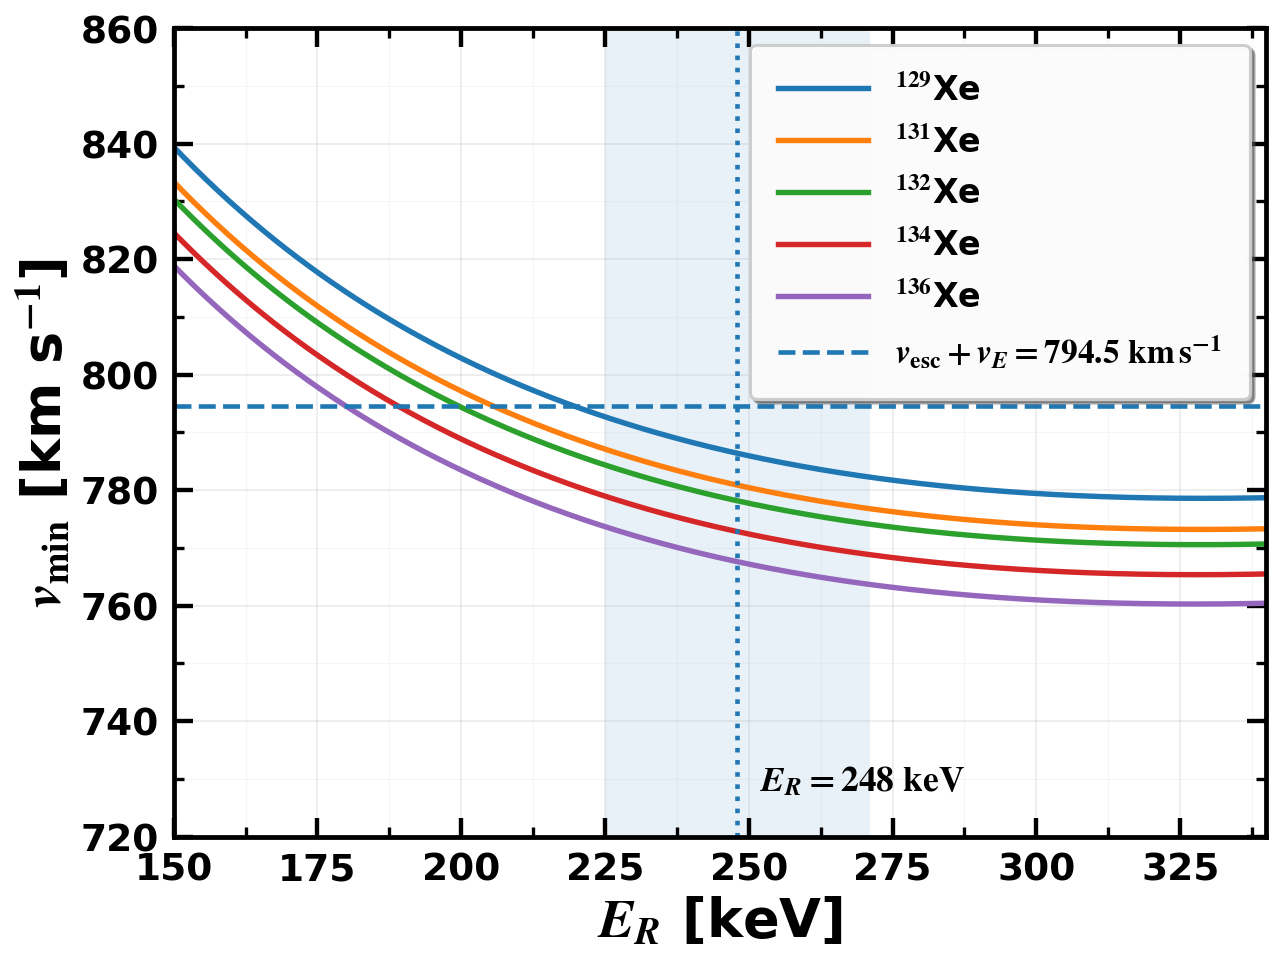

In [8]:

# ============================================================
# Figure 1: v_min(E_R)
# ============================================================

fig, ax = plt.subplots(figsize=(9.4, 7.0))

for A in PLOT_ISOTOPES:
    row = XE.loc[XE["A"] == A].iloc[0]
    vmin_curve = vmin_inelastic_kms(E_FINE, MCHI_BENCH, DELTA_BENCH, row["mass_GeV"])
    ax.plot(E_FINE, vmin_curve, label=rf"$^{{{A}}}$Xe")

ax.axhline(VMAX, linestyle="--", linewidth=2.2, label=fr"$v_{{\rm esc}}+v_E={VMAX:.1f}\ \mathrm{{km\,s^{{-1}}}}$")
ax.axvline(E_CAND, linestyle=":", linewidth=2.2)
ax.axvspan(E_WINDOW[0], E_WINDOW[1], alpha=0.10)

ax.set_xlim(150, 340)
ax.set_ylim(720, 860)

ax.set_xlabel(r"$E_R$ [keV]", fontsize=26, fontweight="bold")
ax.set_ylabel(r"$v_{\min}$ [km s$^{-1}$]", fontsize=26, fontweight="bold")

beautify_axis(ax, legend=True, legend_loc="upper right")

ax.text(252, 728, r"$E_R=248~{\rm keV}$", fontsize=17, fontweight="bold")

save_figure(fig, "fig1_vmin_isotopes")
plt.show()



## 7. Figure 2 — Kinematic-only versus full isotope fractions


Saved: fig2_filtering_decomposition.pdf
Saved: fig2_filtering_decomposition.png


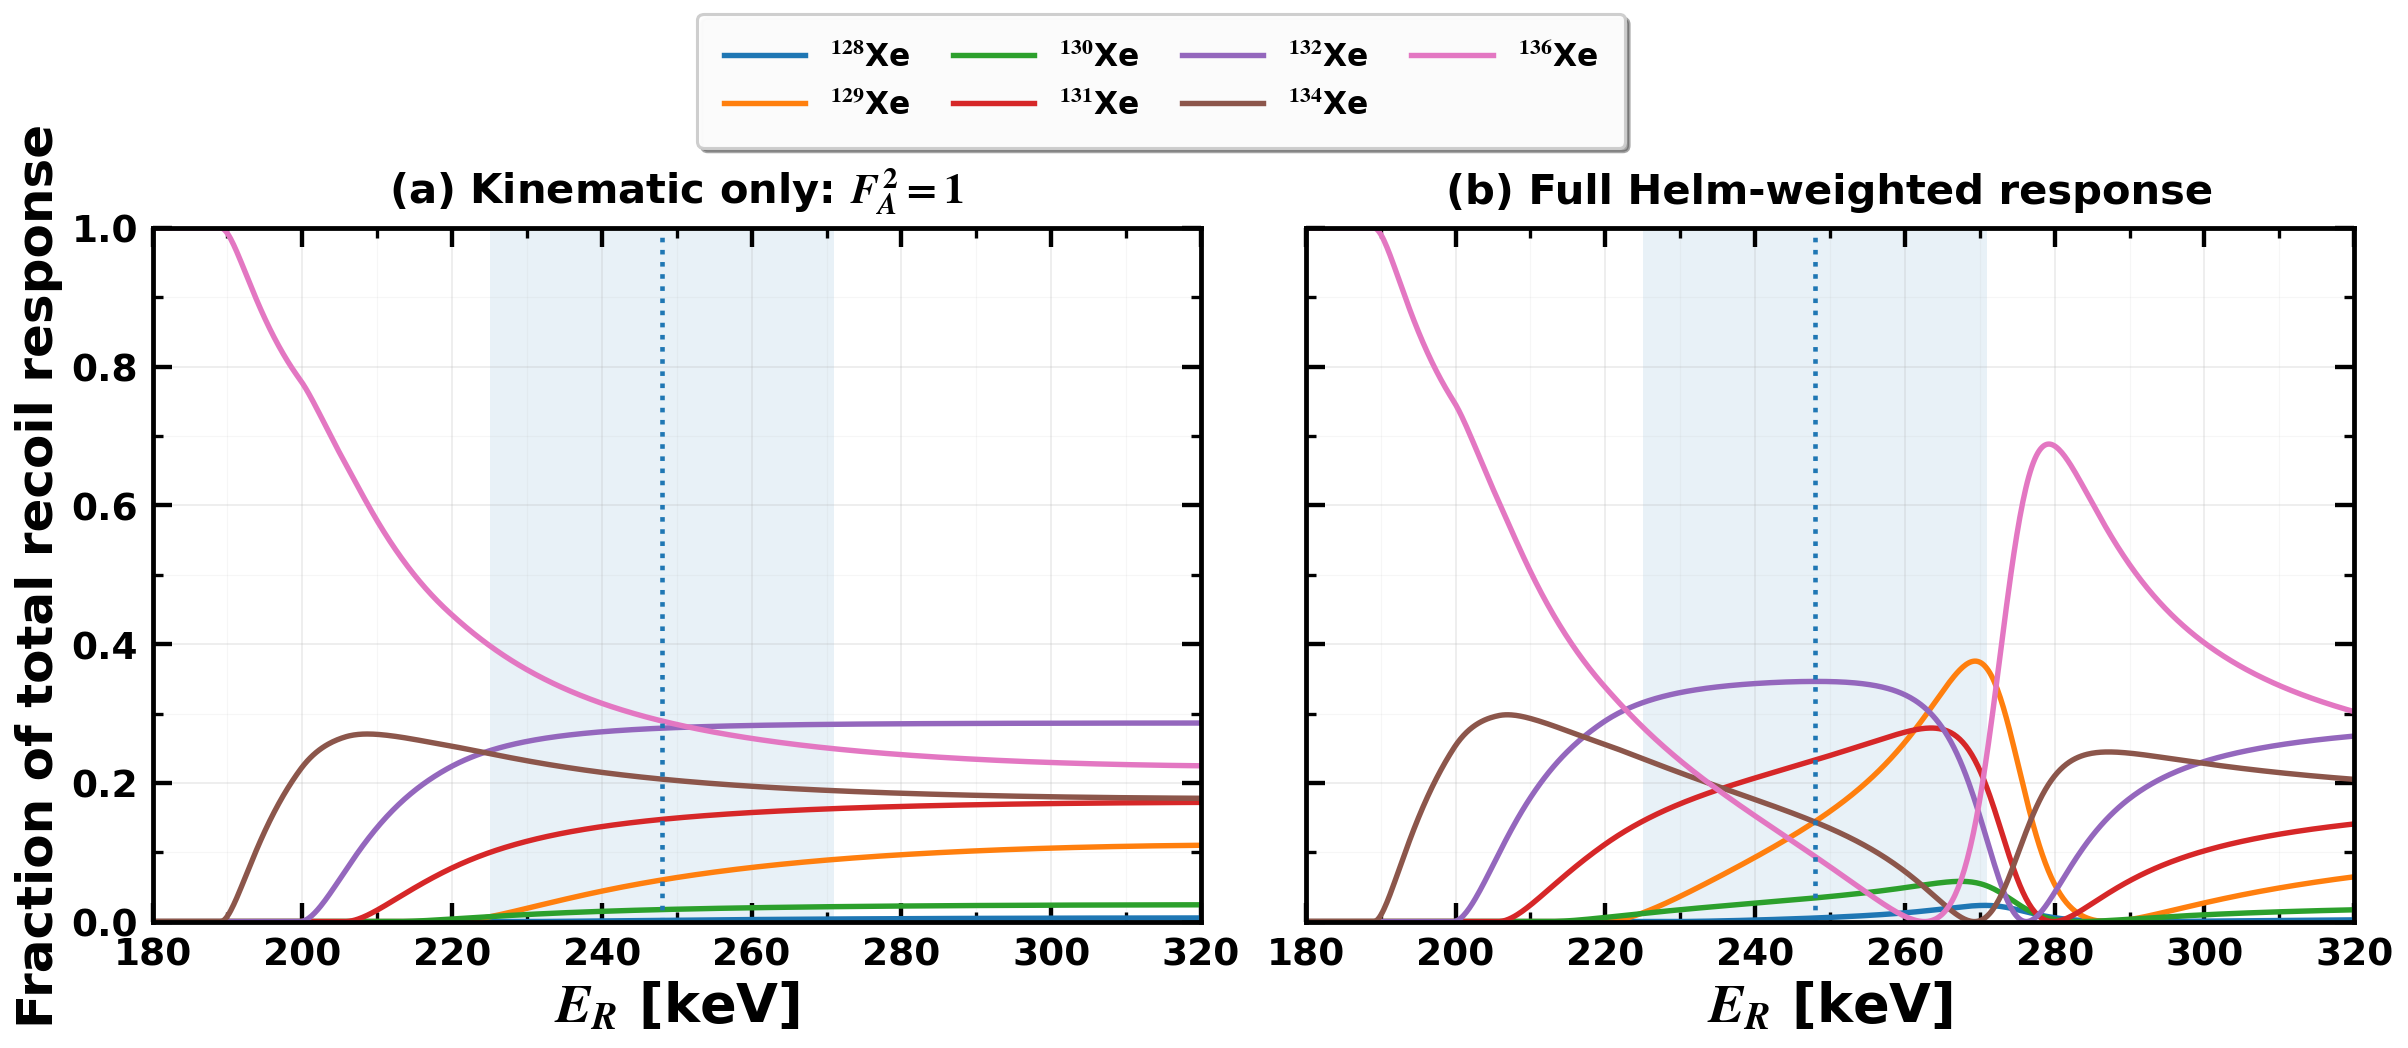

In [9]:
# ============================================================
# Figure 2 FINAL: decomposition
# ============================================================

E_FRAC = np.linspace(160.0, 320.0, 800)

fractions_kin = isotope_fractions(
    E_FRAC, MCHI_BENCH, DELTA_BENCH, halo=HALO, mode="kinematic"
)
fractions_full = isotope_fractions(
    E_FRAC, MCHI_BENCH, DELTA_BENCH, halo=HALO, mode="full"
)

fig, axes = plt.subplots(1, 2, figsize=(16.4, 6.8), sharex=True, sharey=True)

for A in FRACTION_ISOTOPES:
    axes[0].plot(E_FRAC, fractions_kin[A], label=rf"$^{{{A}}}$Xe")
    axes[1].plot(E_FRAC, fractions_full[A], label=rf"$^{{{A}}}$Xe")

for ax in axes:
    ax.axvline(E_CAND, linestyle=":", linewidth=2.2)
    ax.axvspan(E_WINDOW[0], E_WINDOW[1], alpha=0.10)
    ax.set_xlim(180, 320)
    ax.set_ylim(0.0, 1.0)
    ax.set_xlabel(r"$E_R$ [keV]", fontsize=26, fontweight="bold")
    beautify_axis(ax)

axes[0].set_ylabel(
    r"Fraction of total recoil response",
    fontsize=24,
    fontweight="bold",
)

axes[0].set_title(
    r"(a) Kinematic only: $F_A^2=1$",
    fontsize=20,
    fontweight="bold",
    pad=12,
)
axes[1].set_title(
    r"(b) Full Helm-weighted response",
    fontsize=20,
    fontweight="bold",
    pad=12,
)

# One shared boxed legend above the two panels.
handles, labels = axes[0].get_legend_handles_labels()
leg = fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.045),
    ncol=4,
    frameon=True,
    fancybox=True,
    framealpha=0.96,
    shadow=True,
    borderpad=0.85,
    labelspacing=0.55,
    handlelength=2.6,
    columnspacing=1.35,
    prop={"size": 15, "weight": "bold"},
)
style_legend(leg)

plt.subplots_adjust(left=0.09, right=0.985, bottom=0.14, top=0.82, wspace=0.10)
save_figure(fig, "fig2_filtering_decomposition")
plt.show()



## 8. Figure 3 — Dominant-isotope maps in the \((m_\chi,\delta)\) plane


In [10]:

# ============================================================
# Figure 3 support functions
# ============================================================

def integrated_isotope_map(mchi_values, delta_values, *, Emin=225.0, Emax=271.0, nE=120, halo=HALO, include_form_factor=True):
    mchi_values = np.asarray(mchi_values, dtype=float)
    delta_values = np.asarray(delta_values, dtype=float)

    E = np.linspace(Emin, Emax, nE)

    M = mchi_values[None, :, None]
    D = delta_values[:, None, None]
    ER = E[None, None, :]

    responses = []

    for _, row in XE.iterrows():
        A = int(row["A"])
        xi = float(row["abundance"])
        mA = float(row["mass_GeV"])

        mu = reduced_mass(M, mA)
        ER_GeV = ER * 1e-6
        D_GeV = D * 1e-6

        beta_min = ((mA * ER_GeV / mu) + D_GeV) / np.sqrt(2.0 * mA * ER_GeV)
        vmin = beta_min * C_KMS
        eta = eta_shm(vmin, v0=halo["v0"], vesc=halo["vesc"], vE=halo["vE"])

        kernel = xi * mA * A**2 * eta

        if include_form_factor:
            F2 = helm_F2(E, A, mA)[None, None, :]
            kernel = kernel * F2

        integral = np.trapz(kernel, E, axis=-1)
        responses.append(integral)

    return np.stack(responses, axis=0)

def dominant_map_from_integrals(integrals, zero_tol=0.0):
    total = np.sum(integrals, axis=0)
    idx = np.argmax(integrals, axis=0)

    A_array = XE["A"].to_numpy()
    dominant_A = A_array[idx].astype(float)
    dominant_A[total <= zero_tol] = np.nan
    return dominant_A, total

MCHI_GRID = np.linspace(300.0, 2500.0, 141)
DELTA_GRID = np.linspace(250.0, 430.0, 121)

INT_KIN = integrated_isotope_map(MCHI_GRID, DELTA_GRID, include_form_factor=False)
DOM_KIN, TOT_KIN = dominant_map_from_integrals(INT_KIN)

INT_FULL = integrated_isotope_map(MCHI_GRID, DELTA_GRID, include_form_factor=True)
DOM_FULL, TOT_FULL = dominant_map_from_integrals(INT_FULL)


Saved: fig3_dominant_isotope_maps.pdf
Saved: fig3_dominant_isotope_maps.png


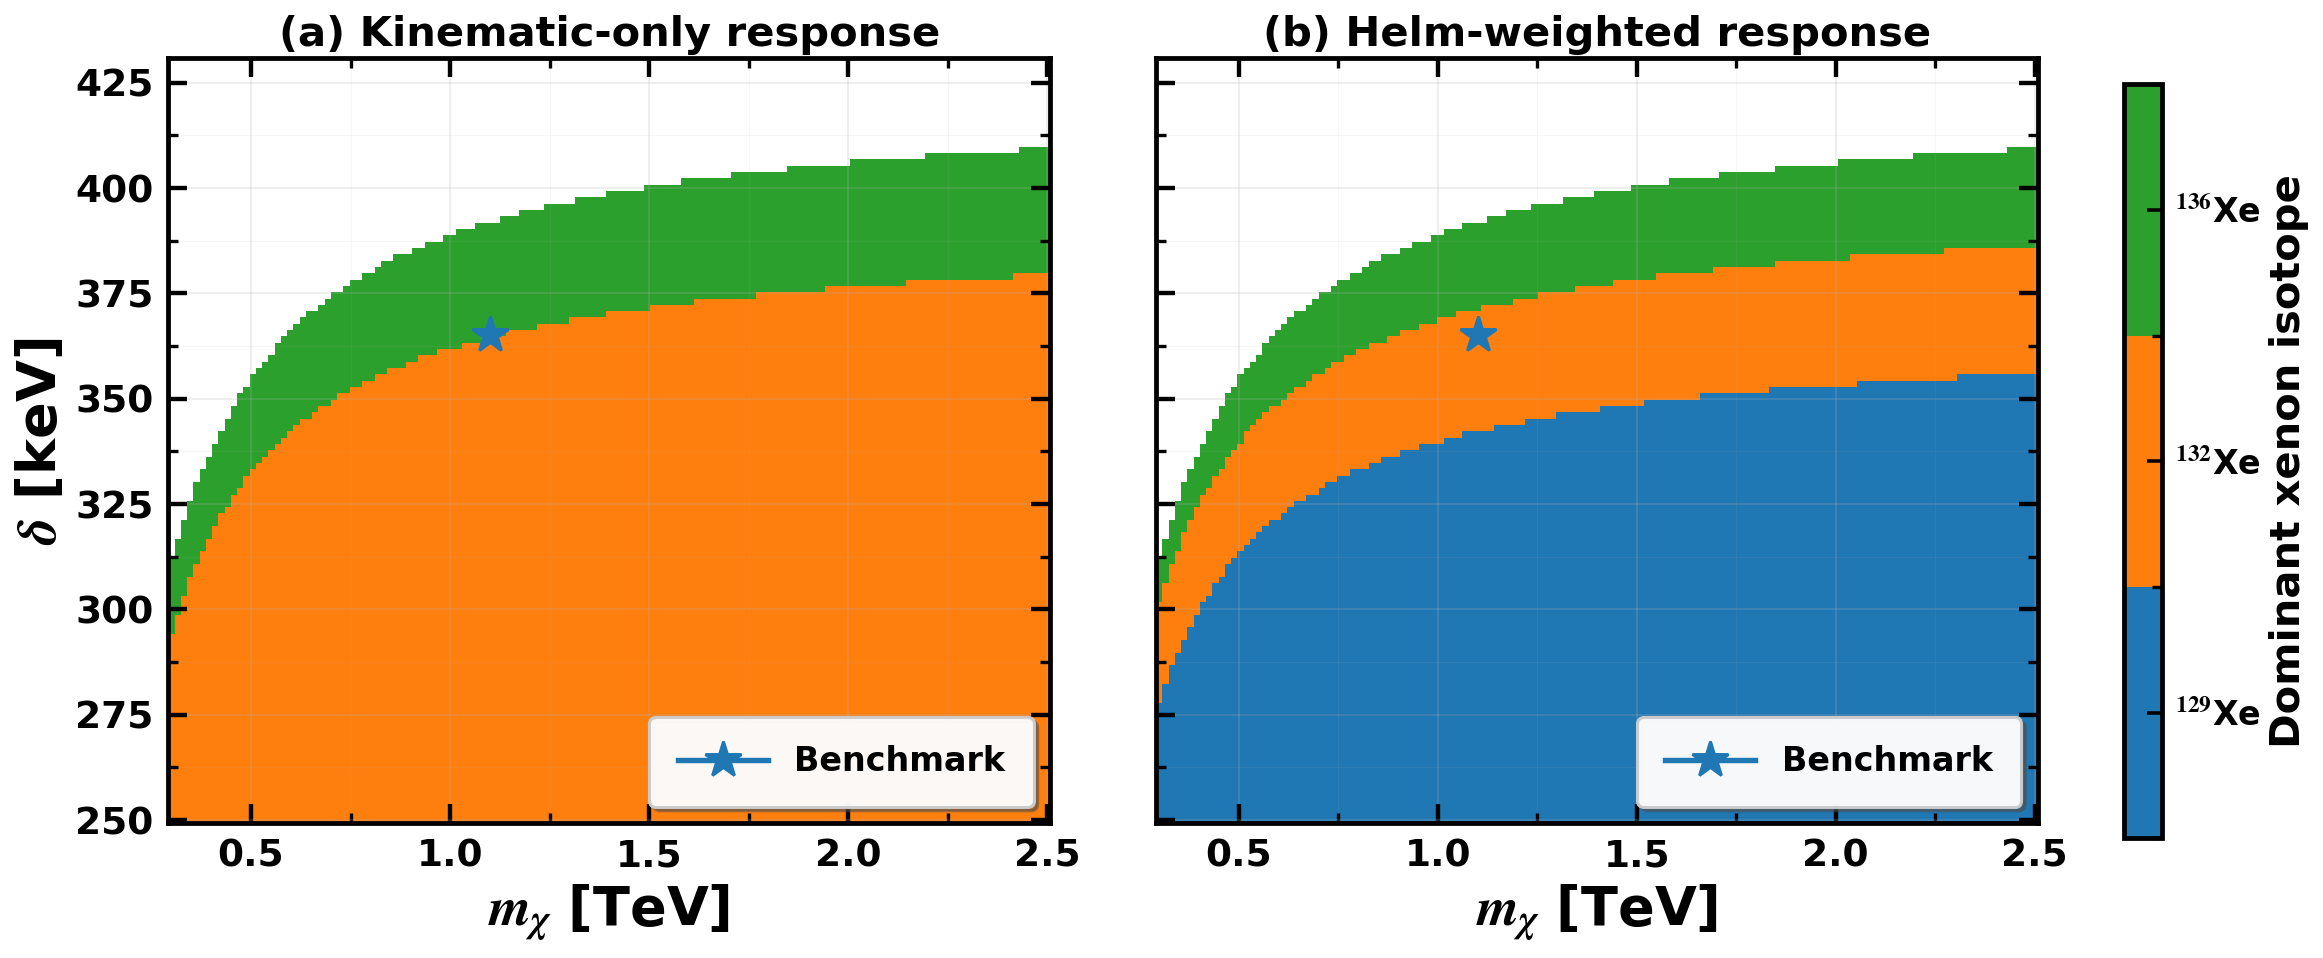

In [11]:

# ============================================================
# Figure 3 FINAL: paired dominant-isotope maps
# ============================================================

present_union = sorted(
    set(int(x) for x in np.unique(DOM_KIN[np.isfinite(DOM_KIN)]))
    |
    set(int(x) for x in np.unique(DOM_FULL[np.isfinite(DOM_FULL)]))
)

cycle_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
map_colors = [cycle_colors[i % len(cycle_colors)] for i in range(len(present_union))]
cmap_shared = ListedColormap(map_colors)

bounds_shared = np.arange(-0.5, len(present_union) + 0.5, 1.0)
norm_shared = BoundaryNorm(bounds_shared, cmap_shared.N)

def category_index_map(dominant_A, categories):
    out = np.full_like(dominant_A, np.nan, dtype=float)
    for i, A in enumerate(categories):
        out[np.isclose(dominant_A, A, equal_nan=False)] = i
    return out

CAT_KIN = category_index_map(DOM_KIN, present_union)
CAT_FULL = category_index_map(DOM_FULL, present_union)

fig, axes = plt.subplots(1, 2, figsize=(16.4, 6.8), sharex=True, sharey=True)

mesh0 = axes[0].pcolormesh(
    MCHI_GRID / 1000.0,
    DELTA_GRID,
    CAT_KIN,
    cmap=cmap_shared,
    norm=norm_shared,
    shading="auto",
    rasterized=True,
)

mesh1 = axes[1].pcolormesh(
    MCHI_GRID / 1000.0,
    DELTA_GRID,
    CAT_FULL,
    cmap=cmap_shared,
    norm=norm_shared,
    shading="auto",
    rasterized=True,
)

for ax in axes:
    ax.plot(MCHI_BENCH / 1000.0, DELTA_BENCH, marker="*", markersize=18, markeredgewidth=1.4, label="Benchmark")
    ax.set_xlabel(r"$m_\chi$ [TeV]", fontsize=26, fontweight="bold")
    beautify_axis(ax, legend=True, legend_loc="lower right")

axes[0].set_ylabel(r"$\delta$ [keV]", fontsize=26, fontweight="bold")
axes[0].set_title("(a) Kinematic-only response", fontsize=20, fontweight="bold")
axes[1].set_title("(b) Helm-weighted response", fontsize=20, fontweight="bold")

cbar = fig.colorbar(mesh1, ax=axes, ticks=np.arange(len(present_union)), pad=0.04, fraction=0.032, shrink=0.96)
cbar.set_label("Dominant xenon isotope", fontsize=20, fontweight="bold")
cbar.ax.set_yticklabels([rf"$^{{{A}}}$Xe" for A in present_union], fontsize=16, fontweight="bold")
cbar.ax.tick_params(direction="in", length=7, width=1.7, pad=6)

plt.subplots_adjust(left=0.08, right=0.84, bottom=0.14, top=0.89, wspace=0.12)
save_figure(fig, "fig3_dominant_isotope_maps")
plt.show()



## 9. Figure 4 — Natural versus isotope-modified xenon


In [12]:

# ============================================================
# Figure 4 data
# ============================================================

NATURAL_COMP = {int(row["A"]): float(row["abundance"]) for _, row in XE.iterrows()}
COMP_CASES = {
    "Natural Xe": NATURAL_COMP,
    r"$^{129}$Xe": {129: 1.0},
    r"$^{132}$Xe": {132: 1.0},
    r"$^{136}$Xe": {136: 1.0},
}

E_COMP = np.linspace(170.0, 330.0, 900)
E_RATE = np.linspace(E_WINDOW[0], E_WINDOW[1], 500)

integrals = {}
for label, comp in COMP_CASES.items():
    spec = composition_kernel(E_RATE, comp, MCHI_BENCH, DELTA_BENCH, halo=HALO, include_form_factor=True)
    integrals[label] = np.trapz(spec, E_RATE)

natural_int = integrals["Natural Xe"]
ratio_labels = list(integrals.keys())
ratio_values = [integrals[label] / natural_int if natural_int > 0.0 else np.nan for label in ratio_labels]

RATIO_TABLE = pd.DataFrame({
    "target": ratio_labels,
    "relative_response": ratio_values,
})
RATIO_TABLE.to_csv(FIGDIR / "composition_response_ratios.csv", index=False)
RATIO_TABLE


,target,relative_response
0,Natural Xe,1
1,$^{129}$Xe,0.40396603
2,$^{132}$Xe,1.234848
3,$^{136}$Xe,1.6934068


Saved: fig4_natural_vs_enriched.pdf
Saved: fig4_natural_vs_enriched.png


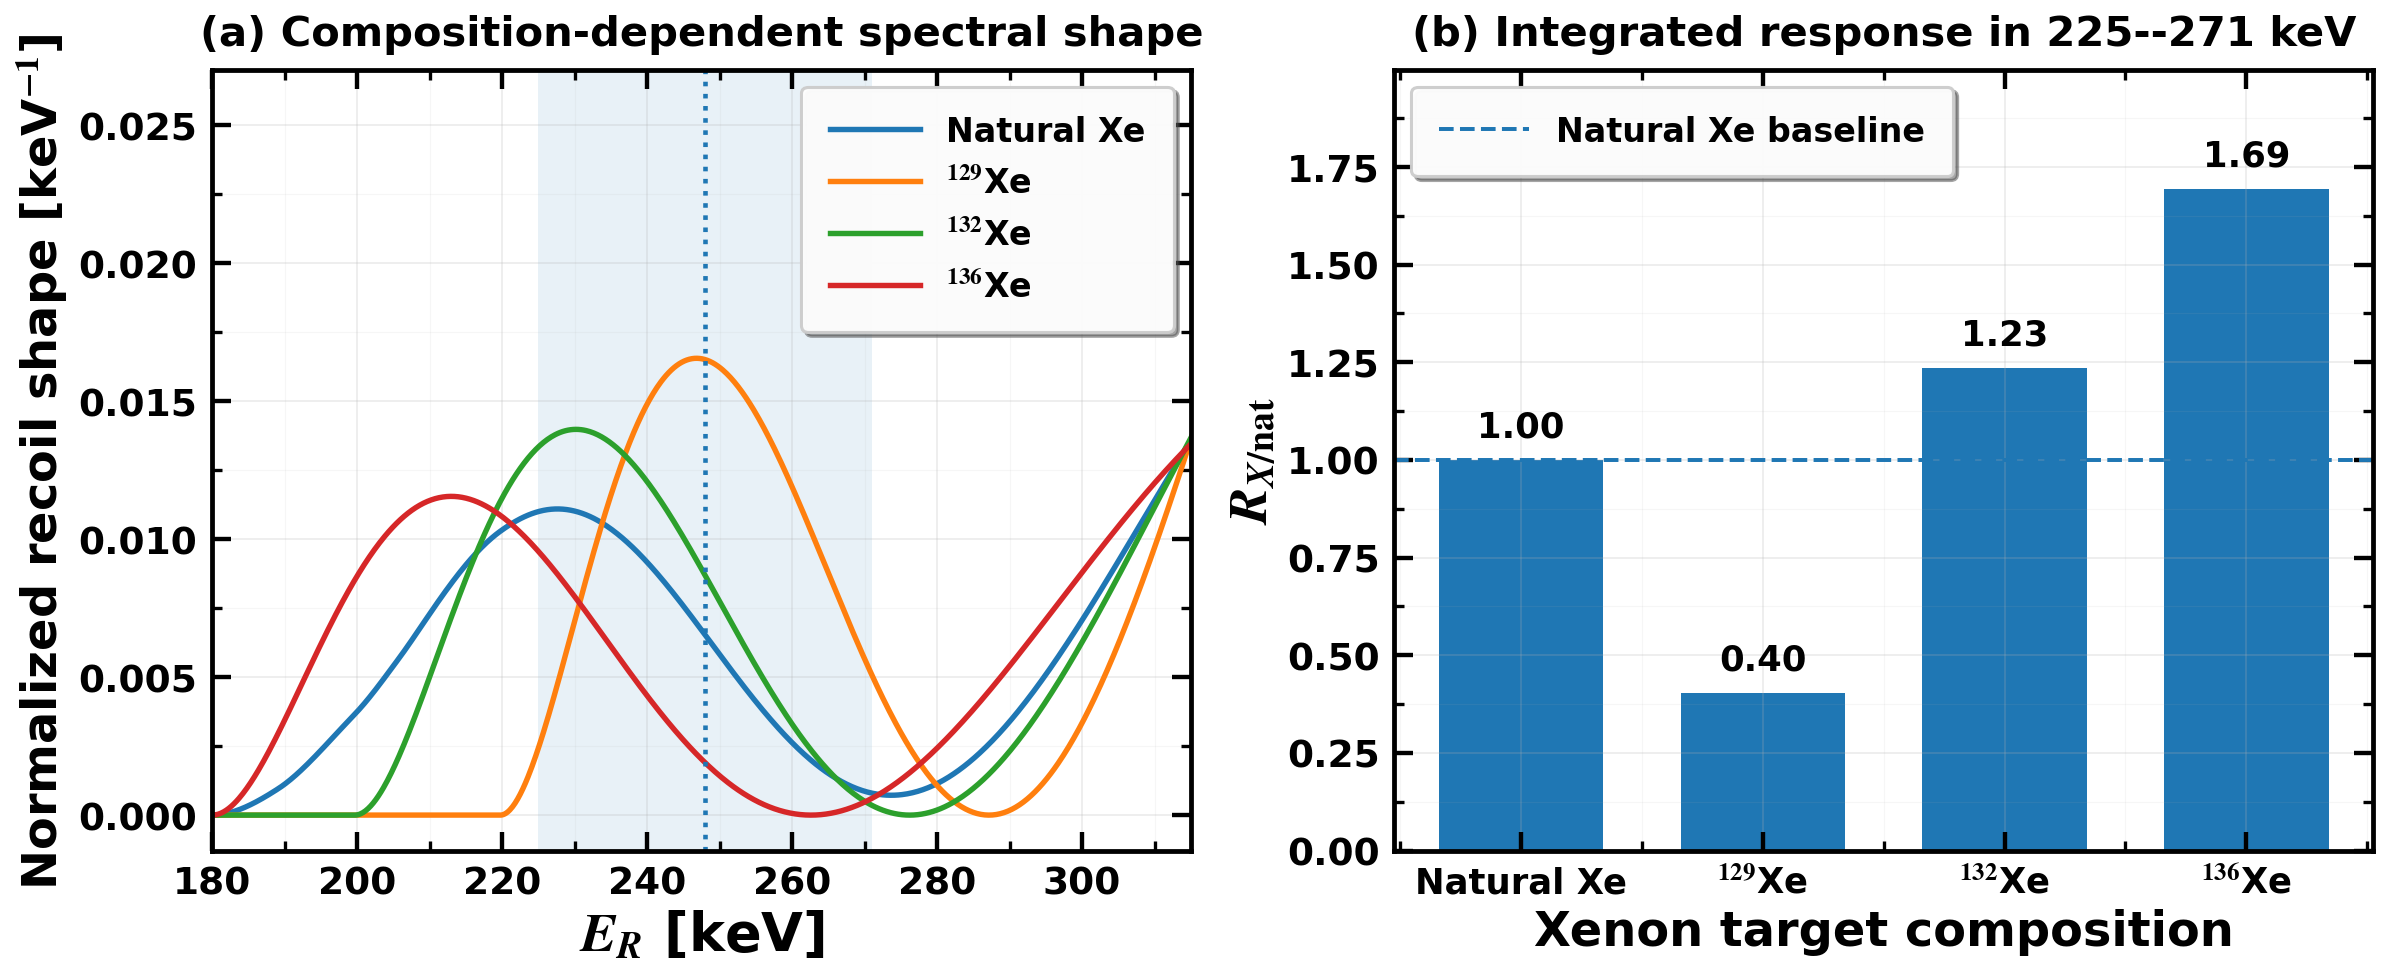

In [13]:
# ============================================================
# Figure 4 FINAL: spectral shape + integrated response
# ============================================================

composition_spectra = {}
for label, comp in COMP_CASES.items():
    composition_spectra[label] = composition_kernel(
        E_COMP,
        comp,
        MCHI_BENCH,
        DELTA_BENCH,
        halo=HALO,
        include_form_factor=True,
    )

fig, axes = plt.subplots(1, 2, figsize=(16.2, 6.8))

# Left: normalized recoil shapes
for label, spec in composition_spectra.items():
    area = np.trapz(spec, E_COMP)
    shape = spec / area if area > 0.0 else np.zeros_like(spec)
    axes[0].plot(E_COMP, shape, label=label)

axes[0].axvline(E_CAND, linestyle=":", linewidth=2.2)
axes[0].axvspan(E_WINDOW[0], E_WINDOW[1], alpha=0.10)
axes[0].set_xlim(180, 315)
axes[0].set_xlabel(r"$E_R$ [keV]", fontsize=26, fontweight="bold")
axes[0].set_ylabel(
    r"Normalized recoil shape [keV$^{-1}$]",
    fontsize=23,
    fontweight="bold",
)
axes[0].set_title(
    "(a) Composition-dependent spectral shape",
    fontsize=20,
    fontweight="bold",
    pad=12,
)
beautify_axis(axes[0], legend=True, legend_loc="upper right")

# Right: integrated response ratios
xpos = np.arange(len(ratio_labels))
bars = axes[1].bar(xpos, ratio_values, width=0.68, linewidth=1.4)

axes[1].axhline(
    1.0,
    linestyle="--",
    linewidth=1.9,
    label="Natural Xe baseline",
)
axes[1].set_xticks(xpos)
axes[1].set_xticklabels(ratio_labels, fontsize=17, fontweight="bold")
axes[1].set_xlabel(
    "Xenon target composition",
    fontsize=23,
    fontweight="bold",
)
axes[1].set_ylabel(
    r"$R_{X/\mathrm{nat}}$",
    fontsize=26,
    fontweight="bold",
)
axes[1].set_title(
    "(b) Integrated response in 225--271 keV",
    fontsize=20,
    fontweight="bold",
    pad=12,
)

ymax = np.nanmax(ratio_values)
axes[1].set_ylim(0.0, 1.18 * ymax)

for bar, value in zip(bars, ratio_values):
    if np.isfinite(value):
        axes[1].text(
            bar.get_x() + bar.get_width() / 2.0,
            value + 0.025 * ymax,
            f"{value:.2f}",
            ha="center",
            va="bottom",
            fontsize=17,
            fontweight="bold",
        )

beautify_axis(axes[1], legend=True, legend_loc="upper left")

plt.tight_layout()
save_figure(fig, "fig4_natural_vs_enriched")
plt.show()



## 10. Figure 5 — Halo robustness


Saved: fig5_halo_robustness.pdf
Saved: fig5_halo_robustness.png


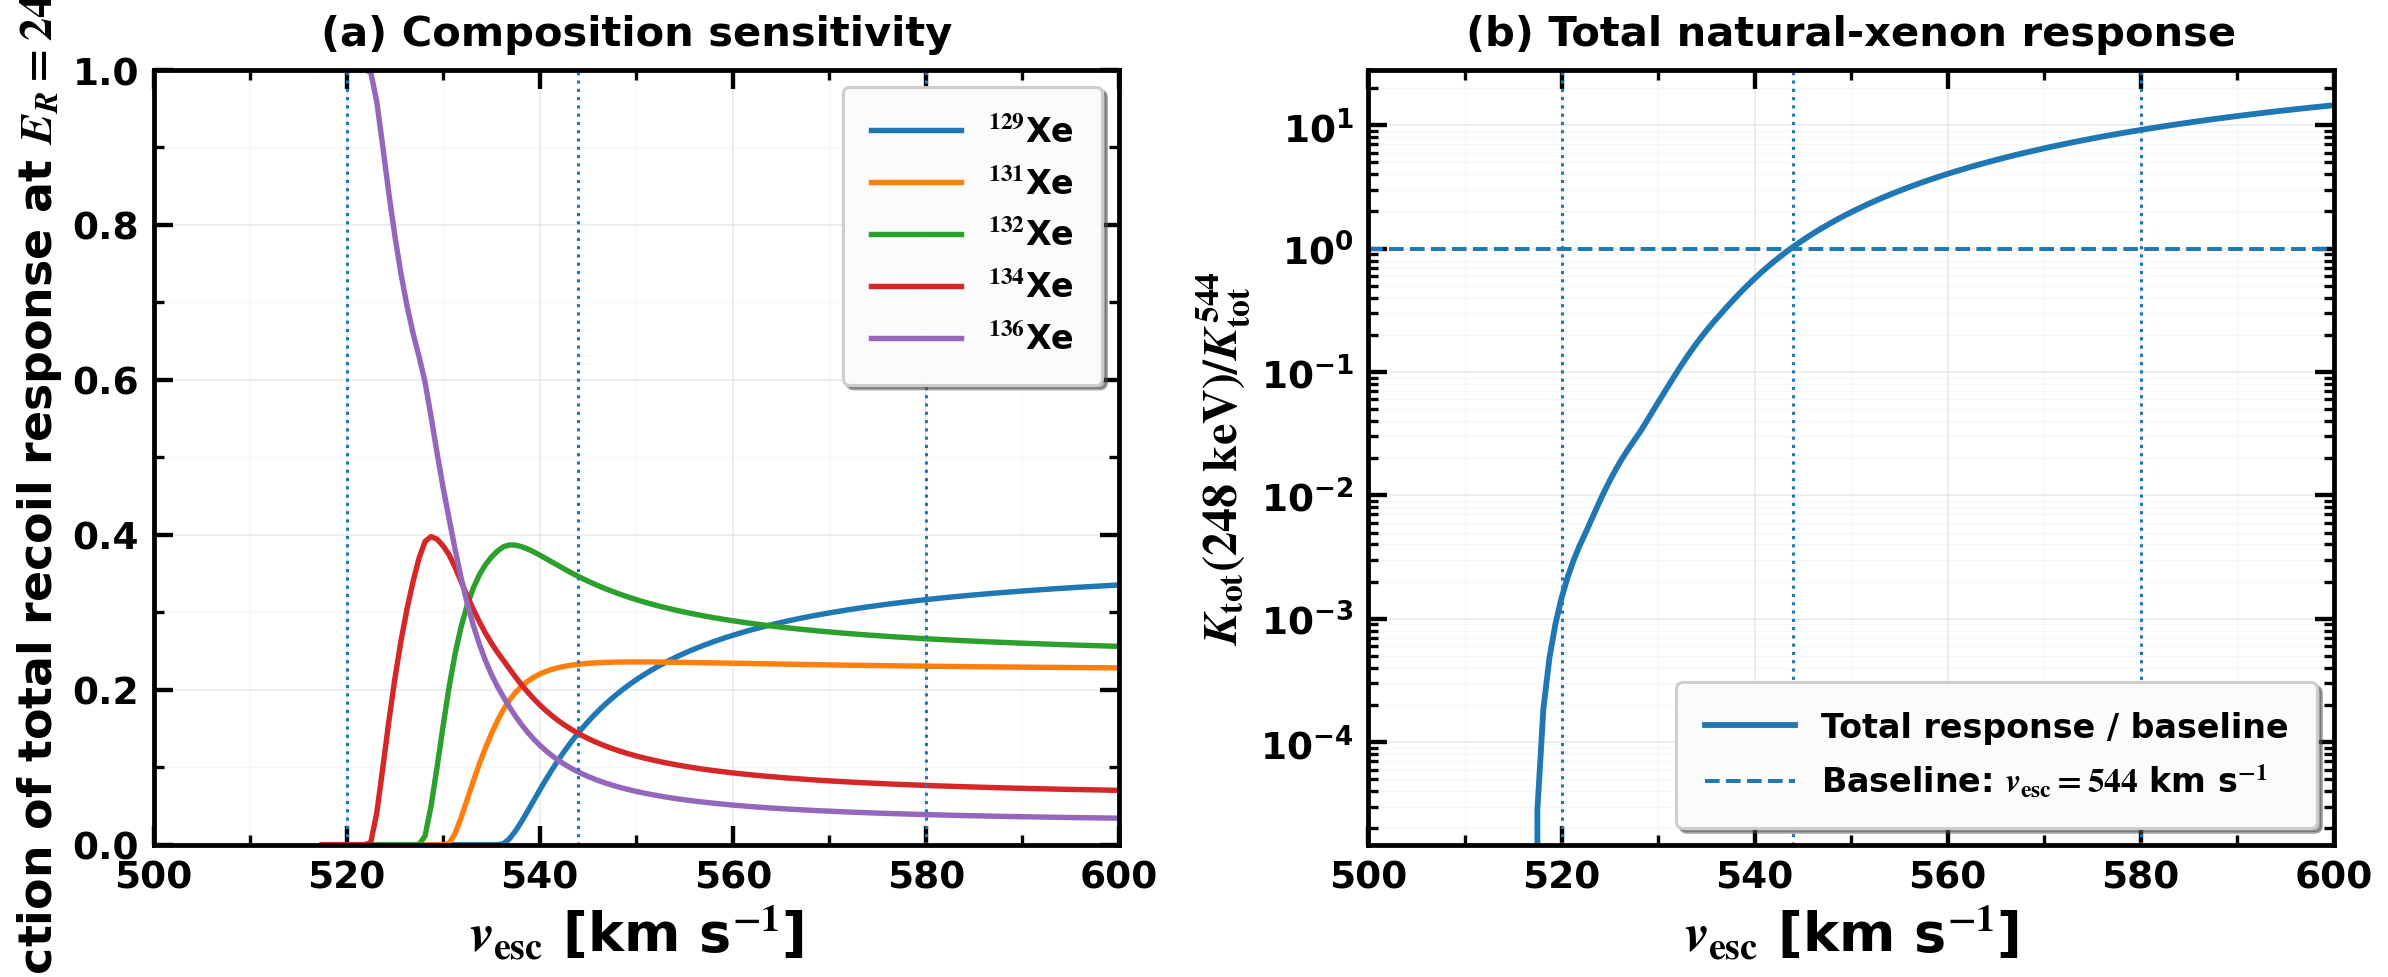

In [14]:
# ============================================================
# Figure 5 FINAL: halo robustness
# ============================================================

VESC_VALUES = np.linspace(500.0, 600.0, 161)

frac_vs_vesc = {A: [] for A in PLOT_ISOTOPES}
total_response_vs_vesc = []

for vesc in VESC_VALUES:
    halo_now = {"v0": HALO["v0"], "vesc": float(vesc), "vE": HALO["vE"]}

    fr = isotope_fractions(
        np.array([E_CAND]),
        MCHI_BENCH,
        DELTA_BENCH,
        halo=halo_now,
        mode="full",
    )
    for A in PLOT_ISOTOPES:
        frac_vs_vesc[A].append(
            float(fr[A][0]) if np.isfinite(fr[A][0]) else np.nan
        )

    k_now = all_isotope_kernels(
        np.array([E_CAND]),
        MCHI_BENCH,
        DELTA_BENCH,
        halo=halo_now,
        include_halo=True,
        include_form_factor=True,
    )

    total_response_vs_vesc.append(
        float(np.nansum([k_now[A][0] for A in k_now]))
    )

total_response_vs_vesc = np.asarray(total_response_vs_vesc, dtype=float)

baseline_idx = np.argmin(np.abs(VESC_VALUES - HALO["vesc"]))
baseline_response = total_response_vs_vesc[baseline_idx]
response_ratio = (
    total_response_vs_vesc / baseline_response
    if baseline_response > 0.0
    else np.full_like(total_response_vs_vesc, np.nan)
)

fig, axes = plt.subplots(1, 2, figsize=(16.2, 6.8))

# Left: isotope fractions
for A in PLOT_ISOTOPES:
    axes[0].plot(
        VESC_VALUES,
        frac_vs_vesc[A],
        label=rf"$^{{{A}}}$Xe",
    )

for vline in [520.0, 544.0, 580.0]:
    axes[0].axvline(vline, linestyle=":", linewidth=1.5)

axes[0].set_xlim(500, 600)
axes[0].set_ylim(0.0, 1.0)
axes[0].set_xlabel(
    r"$v_{\rm esc}$ [km s$^{-1}$]",
    fontsize=26,
    fontweight="bold",
)
axes[0].set_ylabel(
    rf"Fraction of total recoil response at $E_R={E_CAND:.0f}$ keV",
    fontsize=22,
    fontweight="bold",
)
axes[0].set_title(
    "(a) Composition sensitivity",
    fontsize=20,
    fontweight="bold",
    pad=12,
)
beautify_axis(
    axes[0],
    legend=True,
    legend_loc="upper right",
)

# Right: total response
axes[1].semilogy(
    VESC_VALUES,
    response_ratio,
    linewidth=2.8,
    label="Total response / baseline",
)

for vline in [520.0, 544.0, 580.0]:
    axes[1].axvline(vline, linestyle=":", linewidth=1.5)

axes[1].axhline(
    1.0,
    linestyle="--",
    linewidth=1.9,
    label=rf"Baseline: $v_{{\rm esc}}={HALO['vesc']:.0f}$ km s$^{{-1}}$",
)
axes[1].set_xlim(500, 600)
axes[1].set_xlabel(
    r"$v_{\rm esc}$ [km s$^{-1}$]",
    fontsize=26,
    fontweight="bold",
)
axes[1].set_ylabel(
    r"$K_{\rm tot}(248~\mathrm{keV})/K_{\rm tot}^{544}$",
    fontsize=23,
    fontweight="bold",
)
axes[1].set_title(
    "(b) Total natural-xenon response",
    fontsize=20,
    fontweight="bold",
    pad=12,
)

axes[1].yaxis.set_minor_locator(
    LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1)
)
axes[1].yaxis.set_minor_formatter(NullFormatter())

beautify_axis(
    axes[1],
    legend=True,
    legend_loc="lower right",
)

plt.tight_layout()
save_figure(fig, "fig5_halo_robustness")
plt.show()



## 11. Numerical checks


In [15]:

# ============================================================
# 11. Numerical validation
# ============================================================

def run_checks():
    print("Running checks...\n")

    # 1. Abundances
    s = XE["abundance"].sum()
    print("1) Sum of abundances =", s)
    assert np.isclose(s, 1.0, atol=5e-6)

    # 2. Fraction normalization where supported
    Etest = np.linspace(200.0, 290.0, 120)

    for mode in ["kinematic", "full", "nuclear"]:
        fr = isotope_fractions(Etest, MCHI_BENCH, DELTA_BENCH, mode=mode)
        total = np.nansum(np.stack([fr[int(A)] for A in XE["A"]], axis=0), axis=0)

        if mode == "nuclear":
            assert np.allclose(total, 1.0, atol=1e-10)
        else:
            good = (
                np.isclose(total, 1.0, atol=1e-10)
                | np.isnan(total)
                | np.isclose(total, 0.0, atol=1e-10)
            )
            assert np.all(good)

        print(f"2) Fraction normalization passed for {mode}")

    # 3. vmin minimum
    row132 = XE.loc[XE["A"] == 132].iloc[0]
    mA = row132["mass_GeV"]

    Estar = E_star_keV(MCHI_BENCH, DELTA_BENCH, mA)
    vstar = vmin_star_kms(MCHI_BENCH, DELTA_BENCH, mA)
    v_at_Estar = vmin_inelastic_kms(Estar, MCHI_BENCH, DELTA_BENCH, mA)

    print(f"3) E_star(132Xe) = {Estar:.6f} keV")
    print(f"   v_star analytic = {vstar:.6f} km/s")
    print(f"   vmin(E_star)     = {v_at_Estar:.6f} km/s")

    assert np.isclose(vstar, v_at_Estar, rtol=1e-11)

    # 4. Endpoint check
    Emin, Emax = recoil_endpoints_keV(VMAX, MCHI_BENCH, DELTA_BENCH, mA)
    v_low = vmin_inelastic_kms(Emin, MCHI_BENCH, DELTA_BENCH, mA)
    v_high = vmin_inelastic_kms(Emax, MCHI_BENCH, DELTA_BENCH, mA)

    print("4) Endpoint check:")
    print(f"   Eminus = {Emin:.6f} keV -> {v_low:.6f} km/s")
    print(f"   Eplus  = {Emax:.6f} keV -> {v_high:.6f} km/s")
    print(f"   vmax   = {VMAX:.6f} km/s")

    assert np.isclose(v_low, VMAX, rtol=1e-10)
    assert np.isclose(v_high, VMAX, rtol=1e-10)

    # 5. Elastic limit
    E0 = 50.0
    delta0 = 0.0
    v_code = vmin_inelastic_kms(E0, MCHI_BENCH, delta0, mA)

    mu = reduced_mass(MCHI_BENCH, mA)
    E0_GeV = E0 * 1e-6
    v_analytic = np.sqrt(mA * E0_GeV / (2.0 * mu**2)) * C_KMS

    print("5) Elastic limit:")
    print(f"   code     = {v_code:.8f} km/s")
    print(f"   analytic = {v_analytic:.8f} km/s")

    assert np.isclose(v_code, v_analytic, rtol=1e-12)

    # 6. Composition normalization for pure 132Xe
    Ecomp = np.array([248.0])
    pure132 = composition_kernel(Ecomp, {132: 1.0}, MCHI_BENCH, DELTA_BENCH, halo=HALO, include_form_factor=True)[0]

    row132_comp = XE.loc[XE["A"] == 132].iloc[0]
    mA132_comp = float(row132_comp["mass_GeV"])
    v132_comp = vmin_inelastic_kms(Ecomp, MCHI_BENCH, DELTA_BENCH, mA132_comp)

    expected132 = (
        132**2
        * helm_F2(Ecomp, 132, mA132_comp)[0]
        * eta_shm(v132_comp, **HALO)[0]
    )

    print("6) Pure-isotope composition normalization:")
    print(f"   composition_kernel = {pure132:.12e}")
    print(f"   expected           = {expected132:.12e}")

    assert np.isclose(pure132, expected132, rtol=1e-12, atol=0.0)

    print("\nAll checks passed.")

run_checks()


Running checks...

1) Sum of abundances = 1.0
2) Fraction normalization passed for kinematic
2) Fraction normalization passed for full
2) Fraction normalization passed for nuclear
3) E_star(132Xe) = 328.333948 keV
   v_star analytic = 770.548803 km/s
   vmin(E_star)     = 770.548803 km/s
4) Endpoint check:
   Eminus = 199.666678 keV -> 794.500000 km/s
   Eplus  = 539.915736 keV -> 794.500000 km/s
   vmax   = 794.500000 km/s
5) Elastic limit:
   code     = 150.34786391 km/s
   analytic = 150.34786391 km/s
6) Pure-isotope composition normalization:
   composition_kernel = 3.444263707134e-07
   expected           = 3.444263707134e-07

All checks passed.



## 12. Output files


In [16]:

# ============================================================
# 12. List generated files
# ============================================================

for f in sorted(FIGDIR.glob("*")):
    print(f.name)


benchmark_exact_isotope_values.csv
composition_response_ratios.csv
fig1_vmin_isotopes.pdf
fig1_vmin_isotopes.png
fig2_filtering_decomposition.pdf
fig2_filtering_decomposition.png
fig3_dominant_isotope_maps.pdf
fig3_dominant_isotope_maps.png
fig4_natural_vs_enriched.pdf
fig4_natural_vs_enriched.png
fig5_halo_robustness.pdf
fig5_halo_robustness.png
